<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/particle_physics/particle_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Particle Physics* — `particle_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Particle Physics Ch 1 Figures — Colab Notebook
**Particle Physics · Chapter 1: Introduction**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §1.1   | Standard Model particle table — masses, charges, generations |
| fig02  | §1.2   | Energy scales in particle physics — from eV to Planck |
| fig03  | §1.3   | Running coupling constants $\alpha_s$, $\alpha_w$, $\alpha_1$ vs energy |
| fig04  | §1.4   | Timeline of particle physics discoveries |

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Rectangle
import os

BG    = '#1e1e2e'
FG    = '#cdd6f4'
EDGE  = '#45475a'
TEAL  = '#2ec4b6'
BLUE  = '#7ec8e3'
YELL  = '#f9c74f'
GREEN = '#90ee90'
RED   = '#e07070'
PURP  = '#c792ea'
ORAN  = '#ffa657'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': TEAL, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete — Particle Physics Ch 1 figures.')

Setup complete — Particle Physics Ch 1 figures.


---
## fig01 · Standard Model Particle Table (§1.1)

Visual layout of the 17 SM particles: quarks (3 generations × 2), leptons (3 generations × 2), gauge bosons (4), Higgs.

  saved -> figures/ch01/fig01_sm_table.png


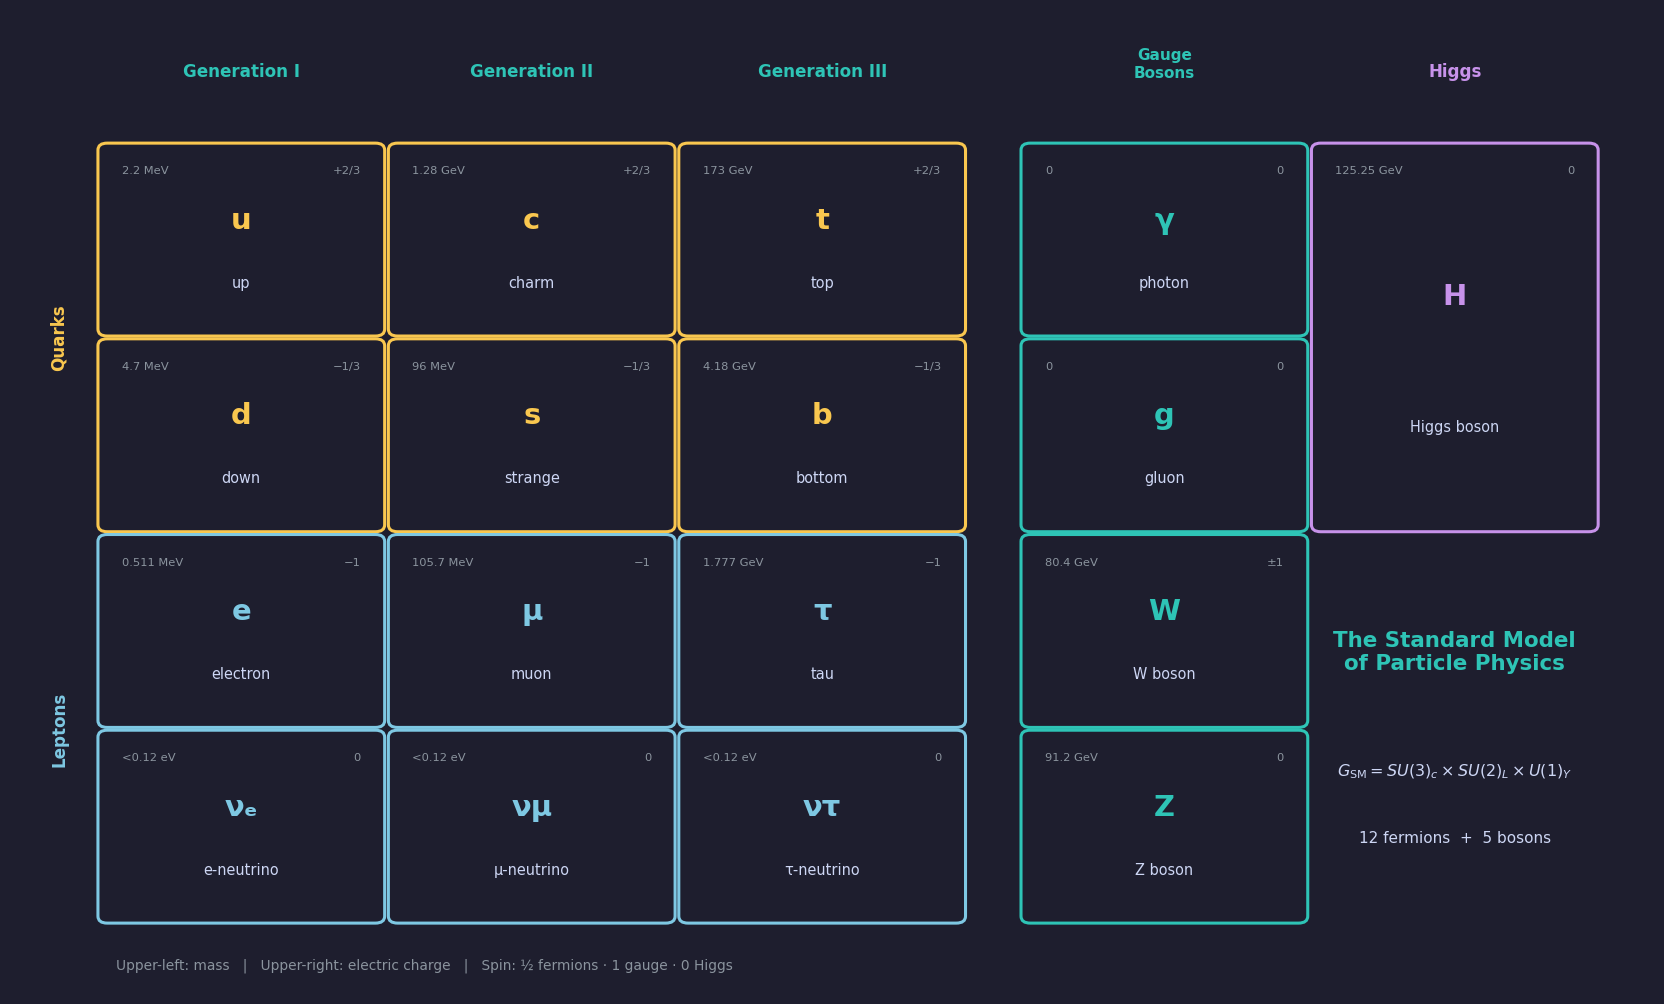

In [30]:
fig, ax = plt.subplots(figsize=(15, 9))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG); ax.axis('off')

BW, BH = 1.45, 1.28   # box width / height
GAP    = 0.12
PAD    = 0.42
FH     = 9

HEADER_Y = FH - 0.50
ROW1_TOP = HEADER_Y - 0.50

def box_top(row):  return ROW1_TOP - row*(BH+GAP)
def box_left(col): return PAD + col*(BW+GAP)

def draw_box(ax, x, y, w, h, symbol, name, mass, charge, color):
    ax.add_patch(FancyBboxPatch((x,y), w, h, boxstyle='round,pad=0.05',
                  facecolor=BG, edgecolor=color, linewidth=2.0))
    ax.text(x+w/2, y+h*0.61, symbol, ha='center', va='center',
            fontsize=19, color=color, fontweight='bold')
    ax.text(x+w/2, y+h*0.26, name, ha='center', va='center',
            fontsize=9.5, color=FG)
    ax.text(x+0.08, y+h-0.11, mass, ha='left', va='top',
            fontsize=7.5, color='#8b949e')
    ax.text(x+w-0.08, y+h-0.11, charge, ha='right', va='top',
            fontsize=7.5, color='#8b949e')

# ── Generation headers ────────────────────────────────────────────────────
for i, gen in enumerate(['Generation I', 'Generation II', 'Generation III']):
    ax.text(box_left(i)+BW/2, HEADER_Y, gen, ha='center', va='bottom',
            fontsize=11, color=TEAL, fontweight='bold')

# ── Fermion grid 4×3 ──────────────────────────────────────────────────────
fermions = [
    [('u','up','2.2 MeV','+2/3',YELL), ('c','charm','1.28 GeV','+2/3',YELL), ('t','top','173 GeV','+2/3',YELL)],
    [('d','down','4.7 MeV','−1/3',YELL), ('s','strange','96 MeV','−1/3',YELL), ('b','bottom','4.18 GeV','−1/3',YELL)],
    [('e','electron','0.511 MeV','−1',BLUE), ('μ','muon','105.7 MeV','−1',BLUE), ('τ','tau','1.777 GeV','−1',BLUE)],
    [('νₑ','e-neutrino','<0.12 eV','0',BLUE), ('νμ','μ-neutrino','<0.12 eV','0',BLUE), ('ντ','τ-neutrino','<0.12 eV','0',BLUE)],
]
for row_i, row in enumerate(fermions):
    for col_i, (sym, name, mass, charge, col) in enumerate(row):
        draw_box(ax, box_left(col_i), box_top(row_i)-BH, BW, BH,
                 sym, name, mass, charge, col)

# Row-group labels
def row_mid(r0, r1): return (box_top(r0) + box_top(r1)-BH) / 2
ax.text(PAD-0.26, row_mid(0,1), 'Quarks',  ha='center', va='center',
        fontsize=11, color=YELL, fontweight='bold', rotation=90)
ax.text(PAD-0.26, row_mid(2,3), 'Leptons', ha='center', va='center',
        fontsize=11, color=BLUE, fontweight='bold', rotation=90)

# ── Gauge bosons col 3 ────────────────────────────────────────────────────
GX = box_left(3) + 0.28
gauge = [('γ','photon','0','0',TEAL), ('g','gluon','0','0',TEAL),
         ('W','W boson','80.4 GeV','±1',TEAL), ('Z','Z boson','91.2 GeV','0',TEAL)]
for row_i, (sym, name, mass, charge, col) in enumerate(gauge):
    draw_box(ax, GX, box_top(row_i)-BH, BW, BH, sym, name, mass, charge, col)
ax.text(GX+BW/2, HEADER_Y, 'Gauge\nBosons', ha='center', va='bottom',
        fontsize=10, color=TEAL, fontweight='bold')

# ── Higgs — spans rows 0-1 ────────────────────────────────────────────────
HX = GX + BW + GAP
higgs_top = box_top(0); higgs_bot = box_top(1)-BH; higgs_h = higgs_top-higgs_bot
draw_box(ax, HX, higgs_bot, BW, higgs_h, 'H', 'Higgs boson', '125.25 GeV', '0', PURP)
ax.text(HX+BW/2, HEADER_Y, 'Higgs', ha='center', va='bottom',
        fontsize=11, color=PURP, fontweight='bold')

# ── Info text — right of Higgs, rows 2-3 ─────────────────────────────────
mid = (box_top(2) + box_top(3)-BH) / 2
ax.text(HX+BW/2, mid+0.55, 'The Standard Model\nof Particle Physics',
        ha='center', va='center', fontsize=14, color=TEAL, fontweight='bold')
ax.text(HX+BW/2, mid-0.30,
        r'$G_{\rm SM}=SU(3)_c\times SU(2)_L\times U(1)_Y$',
        ha='center', va='center', fontsize=10.5, color=FG)
ax.text(HX+BW/2, mid-0.78, '12 fermions  +  5 bosons',
        ha='center', va='center', fontsize=10, color=FG)

# ── Legend ────────────────────────────────────────────────────────────────
ax.text(PAD+0.05, box_top(3)-BH-0.30,
        'Upper-left: mass   |   Upper-right: electric charge'
        '   |   Spin: ½ fermions · 1 gauge · 0 Higgs',
        ha='left', va='top', fontsize=9, color='#8b949e')

ax.set_xlim(-0.1, HX+BW+0.35)
ax.set_ylim(box_top(3)-BH-0.55, FH)
plt.tight_layout(pad=0.2)
save('fig01_sm_table.png', fig)

---
## fig02 · Energy Scales in Particle Physics (§1.2)

  saved -> figures/ch01/fig02_energy_scales.png


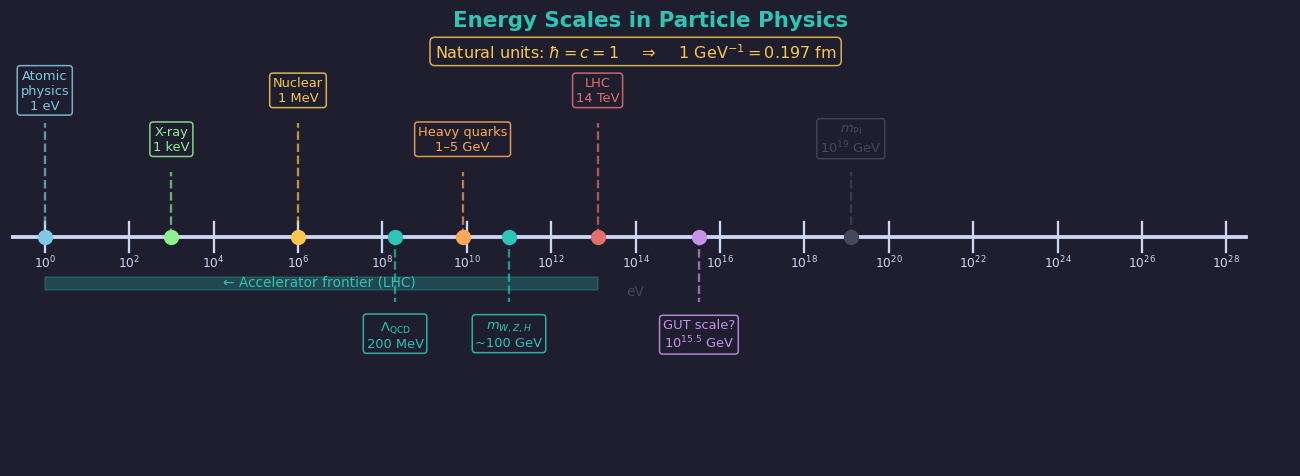

In [31]:
fig, ax = plt.subplots(figsize=(15, 5))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(-0.8, 29.5); ax.set_ylim(-1.0, 4.2)

AXIS_Y = 1.8
ax.axhline(AXIS_Y, xmin=0/29.5, xmax=28.5/29.5, color=FG, lw=2.5, zorder=2)

for log_E in range(0, 29, 2):
    ax.plot([log_E, log_E], [AXIS_Y-0.18, AXIS_Y+0.18], color=FG, lw=1.5)
    ax.text(log_E, AXIS_Y-0.38, f'$10^{{{log_E}}}$', ha='center', fontsize=8, color=FG)
ax.text(14, AXIS_Y-0.72, 'eV', ha='center', fontsize=9, color=EDGE)

scales = [
    (0,    'Atomic\nphysics\n1 eV',           BLUE,  3.6, True),
    (3,    'X-ray\n1 keV',                    GREEN, 3.0, True),
    (6,    'Nuclear\n1 MeV',                  YELL,  3.6, True),
    (8.3,  r'$\Lambda_{\rm QCD}$'+'\n200 MeV',TEAL,  0.6, False),
    (9.9,  'Heavy quarks\n1–5 GeV',           ORAN,  3.0, True),
    (11.0, r'$m_{W,Z,H}$'+'\n~100 GeV',       TEAL,  0.6, False),
    (13.1, 'LHC\n14 TeV',                     RED,   3.6, True),
    (15.5, 'GUT scale?\n$10^{15.5}$ GeV',     PURP,  0.6, False),
    (19.1, r'$m_{\rm Pl}$'+'\n$10^{19}$ GeV', EDGE,  3.0, True),
]
for log_E, lbl, col, y_box, above in scales:
    stem_end = y_box - 0.40 if above else y_box + 0.40
    ax.plot([log_E, log_E], [AXIS_Y, stem_end], color=col, lw=1.5, ls='--', alpha=0.7)
    ax.plot(log_E, AXIS_Y, 'o', color=col, ms=9, zorder=5)
    ax.text(log_E, y_box, lbl, ha='center', va='center', fontsize=8.5, color=col,
            bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=col, alpha=0.88))

ax.axvspan(0, 13.1, ymin=(AXIS_Y-0.06)/4.2, ymax=(AXIS_Y+0.06)/4.2,
           color=TEAL, alpha=0.25, zorder=1)
ax.text(6.5, AXIS_Y-0.60, '← Accelerator frontier (LHC)', ha='center',
        fontsize=9, color=TEAL)
ax.text(14, 4.0, r'Natural units: $\hbar=c=1$    $\Rightarrow$    1 GeV$^{-1}=0.197$ fm',
        ha='center', fontsize=10.5, color=YELL,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELL, alpha=0.85))
ax.set_title('Energy Scales in Particle Physics', fontsize=14, color=TEAL, pad=10)
save('fig02_energy_scales.png', fig)


---
## fig03 · Running Coupling Constants (§1.3)

  saved -> figures/ch01/fig03_running_couplings.png


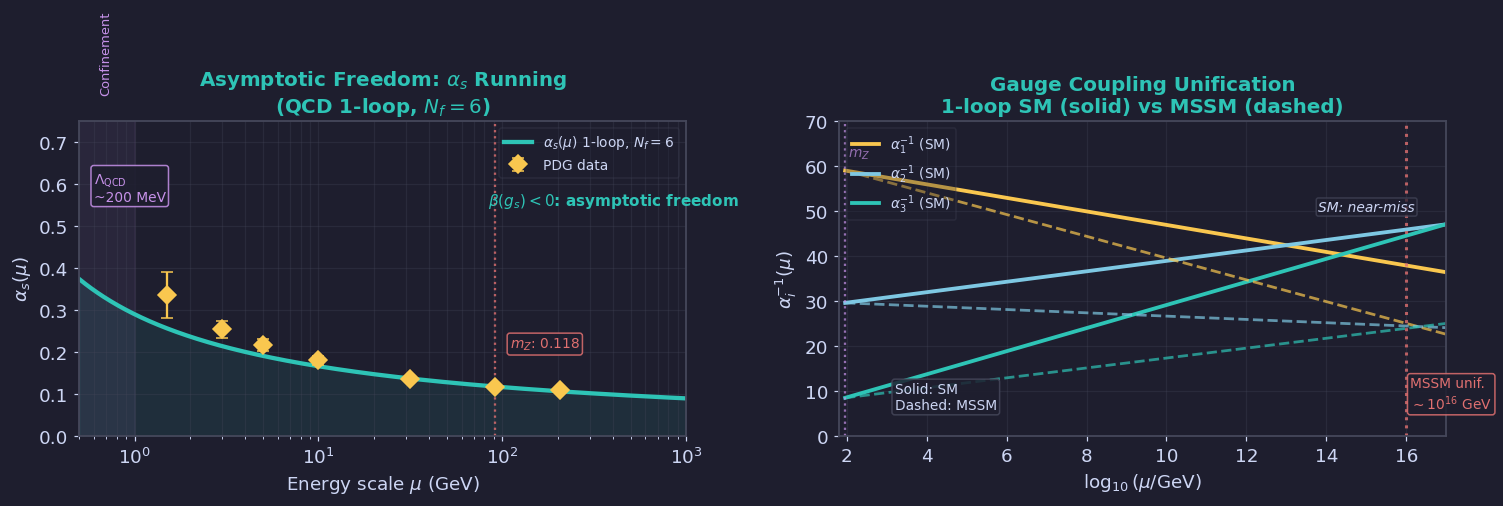

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# ── Left: alpha_s running (1-loop QCD, proper formula) ────────────────────
ax = axes[0]; ax.set_facecolor(BG)

mZ = 91.2; as_mZ = 0.118; b0 = 7.0   # b0 = 11 - 2*Nf/3, Nf=6
mu_arr = np.logspace(np.log10(0.5), np.log10(1000), 500)
# 1-loop: alpha_s(mu) = alpha_s(mZ) / (1 + alpha_s(mZ)*b0/(2pi)*ln(mu/mZ))
alpha_s = as_mZ / (1 + as_mZ*b0/(2*np.pi)*np.log(mu_arr/mZ))
alpha_s = np.clip(alpha_s, 0.04, 0.95)

ax.semilogx(mu_arr, alpha_s, color=TEAL, lw=2.8, label=r'$\alpha_s(\mu)$ 1-loop, $N_f{=}6$')
ax.fill_between(mu_arr, 0, alpha_s, color=TEAL, alpha=0.10)

# PDG data (selected measurements)
data_mu  = [1.5, 3.0, 5.0, 10., 31.6, 91.2, 206.]
data_as  = [0.336,0.254,0.217,0.180,0.136,0.118,0.110]
data_err = [0.054,0.020,0.015,0.010,0.006,0.002,0.004]
ax.errorbar(data_mu, data_as, yerr=data_err, fmt='D', color=YELL,
            ms=8, capsize=4, elinewidth=1.5, label='PDG data', zorder=5)

ax.axvline(0.21, color=PURP, lw=1.5, ls=':', alpha=0.8)
ax.text(0.60, 0.56, r'$\Lambda_{\rm QCD}$'+'\n~200 MeV', fontsize=9, color=PURP,
        bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=PURP,alpha=0.85))
ax.axvline(91.2, color=RED, lw=1.5, ls=':', alpha=0.8)
ax.text(110, 0.21, r'$m_Z$'+': 0.118', fontsize=9, color=RED,
        bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=RED,alpha=0.85))
ax.axvspan(0.5, 1.0, color=PURP, alpha=0.07)
ax.text(0.7, 0.82, 'Confinement', fontsize=8.5, color=PURP, ha='center', rotation=90)
ax.text(400, 0.55, r'$\beta(g_s)<0$: asymptotic freedom', fontsize=10,
        color=TEAL, fontweight='bold', ha='center')
ax.set_xlabel(r'Energy scale $\mu$ (GeV)'); ax.set_ylabel(r'$\alpha_s(\mu)$')
ax.set_title(r'Asymptotic Freedom: $\alpha_s$ Running'+'\n(QCD 1-loop, $N_f=6$)')
ax.legend(fontsize=9, labelcolor=FG)
ax.set_xlim(0.5, 1000); ax.set_ylim(0, 0.75)
ax.grid(True, which='both', alpha=0.3)

# ── Right: gauge coupling unification (1-loop SM vs MSSM) ─────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)

log_mZ = np.log10(mZ)
log_mu = np.linspace(log_mZ, 17, 400)
dl = (log_mu - log_mZ) * np.log(10)   # ln(mu/m_Z)

# SM 1-loop: beta coefficients (GUT-normalised hypercharge)
# b1=41/10, b2=-19/6, b3=-7  →  alpha_i^{-1} increases/decreases accordingly
b1_SM, b2_SM, b3_SM = 41/10, -19/6, -7.0
a1_SM = 59.0 - b1_SM/(2*np.pi)*dl   # alpha_1^{-1}(m_Z)=59
a2_SM = 29.6 - b2_SM/(2*np.pi)*dl   # alpha_2^{-1}(m_Z)=29.6
a3_SM =  8.5 - b3_SM/(2*np.pi)*dl   # alpha_3^{-1}(m_Z)=8.5

# MSSM 1-loop: b1=33/5, b2=1, b3=-3
b1_MS, b2_MS, b3_MS = 33/5, 1.0, -3.0
a1_MS = 59.0 - b1_MS/(2*np.pi)*dl
a2_MS = 29.6 - b2_MS/(2*np.pi)*dl
a3_MS =  8.5 - b3_MS/(2*np.pi)*dl

ax2.plot(log_mu, a1_SM, color=YELL, lw=2.5, label=r'$\alpha_1^{-1}$ (SM)')
ax2.plot(log_mu, a2_SM, color=BLUE,  lw=2.5, label=r'$\alpha_2^{-1}$ (SM)')
ax2.plot(log_mu, a3_SM, color=TEAL,  lw=2.5, label=r'$\alpha_3^{-1}$ (SM)')
ax2.plot(log_mu, a1_MS, color=YELL, lw=1.8, ls='--', alpha=0.70)
ax2.plot(log_mu, a2_MS, color=BLUE,  lw=1.8, ls='--', alpha=0.70)
ax2.plot(log_mu, a3_MS, color=TEAL,  lw=1.8, ls='--', alpha=0.70)

ax2.axvline(16.0, color=RED, lw=2, ls=':', alpha=0.8)
ax2.text(16.1, 6, 'MSSM unif.\n$\\sim10^{16}$ GeV', fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=RED,alpha=0.85))
ax2.axvline(log_mZ, color=PURP, lw=1.5, ls=':', alpha=0.7)
ax2.text(log_mZ+0.08, 62, r'$m_Z$', fontsize=9, color=PURP)
ax2.text(13.8, 50, 'SM: near-miss', fontsize=9, color=FG, style='italic',
         bbox=dict(boxstyle='round,pad=0.15',fc=BG,ec=EDGE,alpha=0.7))
ax2.text(3.2, 6, 'Solid: SM\nDashed: MSSM', fontsize=9, color=FG,
         bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=EDGE,alpha=0.85))
ax2.set_xlabel(r'$\log_{10}(\mu/\mathrm{GeV})$')
ax2.set_ylabel(r'$\alpha_i^{-1}(\mu)$')
ax2.set_title('Gauge Coupling Unification\n1-loop SM (solid) vs MSSM (dashed)')
ax2.legend(fontsize=9, labelcolor=FG, loc='upper left')
ax2.set_xlim(log_mZ-0.15, 17); ax2.set_ylim(0, 70)
ax2.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig03_running_couplings.png', fig)


---
## fig04 · Timeline of Particle Physics Discoveries (§1.4)

  saved -> figures/ch01/fig04_timeline.png


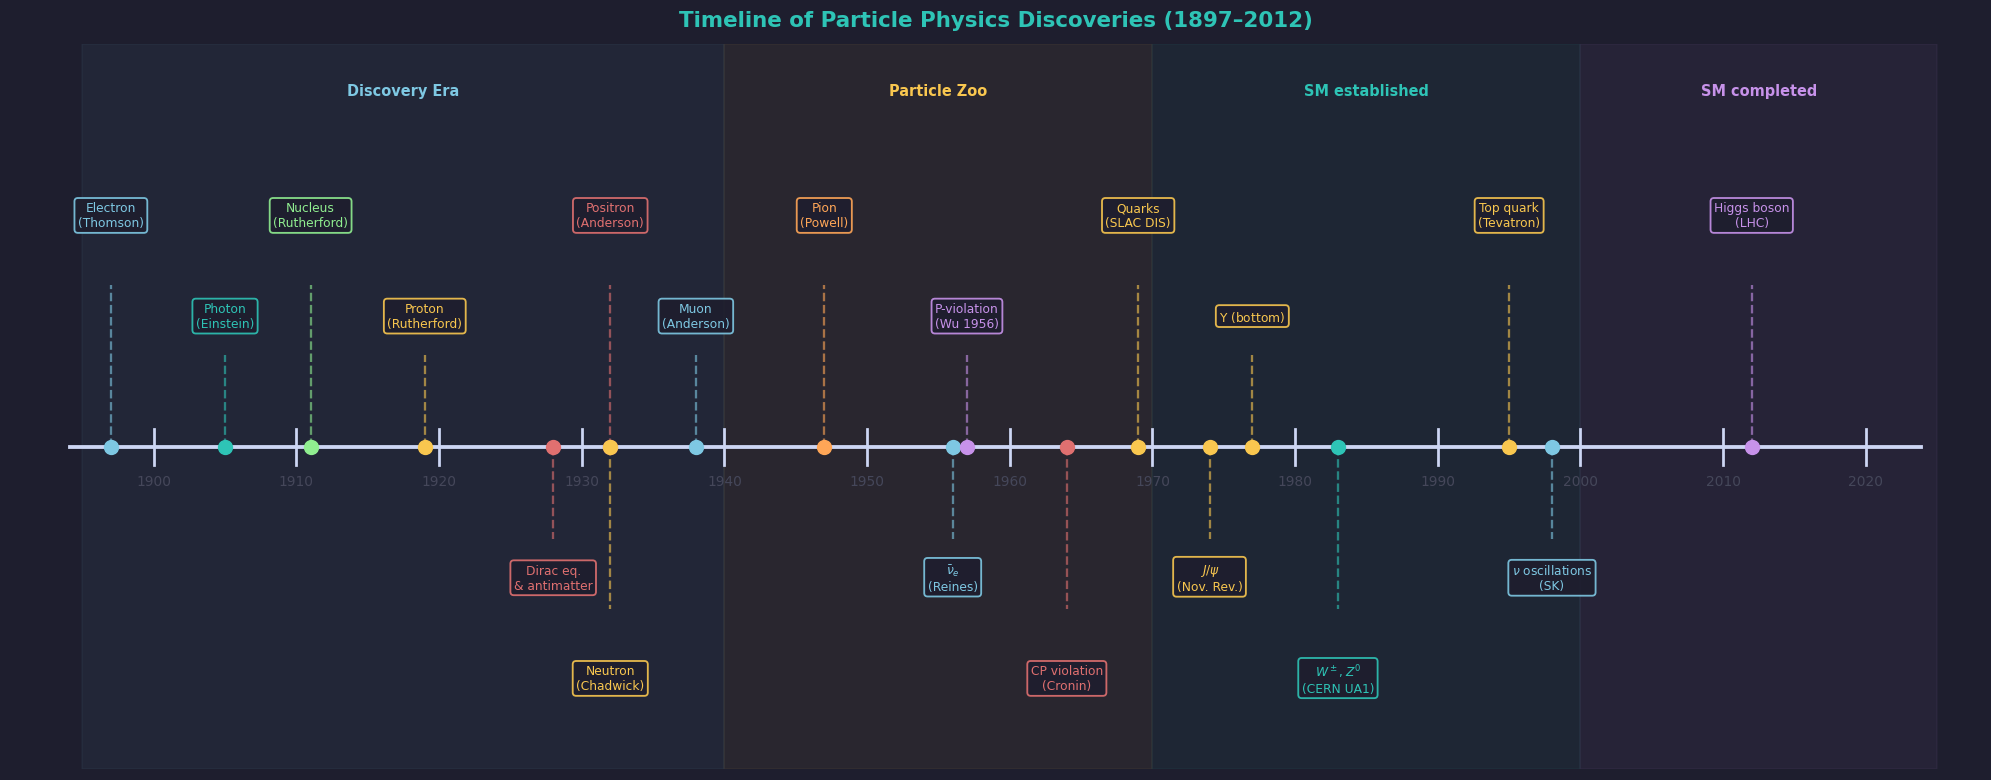

In [33]:
fig, ax = plt.subplots(figsize=(18, 7))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(1890, 2028); ax.set_ylim(-3.2, 4.0)

AXIS_Y = 0.0
ax.axhline(AXIS_Y, xmin=0.03, xmax=0.97, color=FG, lw=2.5, zorder=2)

for yr in range(1900, 2025, 10):
    ax.plot([yr,yr],[AXIS_Y-0.18,AXIS_Y+0.18], color=FG, lw=1.8)
    ax.text(yr, AXIS_Y-0.38, str(yr), ha='center', fontsize=9, color=EDGE)

events = [
    (1897, 'Electron\n(Thomson)',          2.3, BLUE),
    (1905, 'Photon\n(Einstein)',           1.3, TEAL),
    (1911, 'Nucleus\n(Rutherford)',        2.3, GREEN),
    (1919, 'Proton\n(Rutherford)',         1.3, YELL),
    (1928, 'Dirac eq.\n& antimatter',     -1.3, RED),
    (1932, 'Positron\n(Anderson)',         2.3, RED),
    (1932, 'Neutron\n(Chadwick)',         -2.3, YELL),
    (1938, 'Muon\n(Anderson)',             1.3, BLUE),
    (1947, 'Pion\n(Powell)',               2.3, ORAN),
    (1956, r'$\bar\nu_e$'+'\n(Reines)',   -1.3, BLUE),
    (1957, 'P-violation\n(Wu 1956)',       1.3, PURP),
    (1964, 'CP violation\n(Cronin)',      -2.3, RED),
    (1969, 'Quarks\n(SLAC DIS)',           2.3, YELL),
    (1974, r'$J/\psi$'+'\n(Nov. Rev.)',   -1.3, YELL),
    (1977, r'$\Upsilon$ (bottom)',         1.3, YELL),
    (1983, r'$W^\pm,Z^0$'+'\n(CERN UA1)', -2.3, TEAL),
    (1995, 'Top quark\n(Tevatron)',        2.3, YELL),
    (1998, r'$\nu$ oscillations'+'\n(SK)',-1.3, BLUE),
    (2012, 'Higgs boson\n(LHC)',           2.3, PURP),
]
for yr, lbl, y, col in events:
    ax.plot([yr,yr],[AXIS_Y, y*0.70], color=col, lw=1.5, ls='--', alpha=0.6)
    ax.plot(yr, AXIS_Y, 'o', color=col, ms=9, zorder=5)
    ax.text(yr, y, lbl, ha='center', va='center', fontsize=8, color=col,
            bbox=dict(boxstyle='round,pad=0.28', fc=BG, ec=col, alpha=0.90, linewidth=1.2))

eras = [
    (1895,1940,'Discovery Era',  BLUE),
    (1940,1970,'Particle Zoo',   YELL),
    (1970,2000,'SM established', TEAL),
    (2000,2025,'SM completed',   PURP),
]
for x0,x1,lbl,col in eras:
    ax.axvspan(x0, x1, color=col, alpha=0.05)
    ax.text((x0+x1)/2, 3.5, lbl, ha='center', fontsize=9.5, color=col, fontweight='bold')

ax.set_title('Timeline of Particle Physics Discoveries (1897–2012)',
             fontsize=14, color=TEAL, pad=12)
plt.tight_layout(pad=0.3)
save('fig04_timeline.png', fig)


In [34]:
import shutil
from google.colab import files

shutil.make_archive('particle_ch01_figures', 'zip', '.', 'figures')
files.download('particle_ch01_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>